In [2]:
import pandas as pd 

df = pd.read_csv("../data/raw/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
cols = ["person_age", "person_income", "loan_amnt",
        "loan_int_rate", "loan_percent_income"]

pd.options.display.float_format = "{:,.2f}".format   # supaya income tidak jadi 1e6

summary = df.groupby("loan_status")[cols].describe().T
summary.columns = ["Lancar (0)", "Gagal Bayar (1)"]
summary

Lancar (0)  Gagal Bayar (1)
person_age          count    25,473.00         7,108.00
                    mean         27.81            27.47
                    std           6.37             6.26
                    min          20.00            20.00
                    25%          23.00            23.00
                    50%          26.00            26.00
                    75%          30.00            30.00
                    max         144.00            70.00
person_income       count    25,473.00         7,108.00
                    mean     70,804.36        49,125.65
                    std      66,568.80        36,907.38
                    min       7,000.00         4,000.00
                    25%      42,000.00        30,000.00
                    50%      60,000.00        41,498.00
                    75%      84,000.00        59,497.75
                    max   6,000,000.00       703,800.00
loan_amnt           count    25,473.00         7,108.00
                    mean      9,237.46        10,850.50
                    std       6,026.38         7,143.35
                    min         500.00           900.00
                    25%       5,000.00         5,000.00
                    50%       8,000.00         9,600.00
                    75%      12,000.00        15,000.00
                    max      35,000.00        35,000.00
loan_int_rate       count    23,001.00         6,464.00
                    mean         10.44            13.06
                    std           2.98             3.29
                    min           5.42             5.42
                    25%           7.68            10.74
                    50%          10.59            13.49
                    75%          12.69            15.58
                    max          22.06            23.22
loan_percent_income count    25,473.00         7,108.00
                    mean          0.15             0.25
                    std           0.09             0.13
                    min           0.00             0.01
                    25%           0.08             0.14
                    50%           0.13             0.24
                    75%           0.20             0.34
                    max           0.83             0.78

C:\Users\APTIKA\AppData\Local\Temp\ipykernel_22296\369994657.py:16: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\APTIKA 2025\RIMA\credit-risk-predicition\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


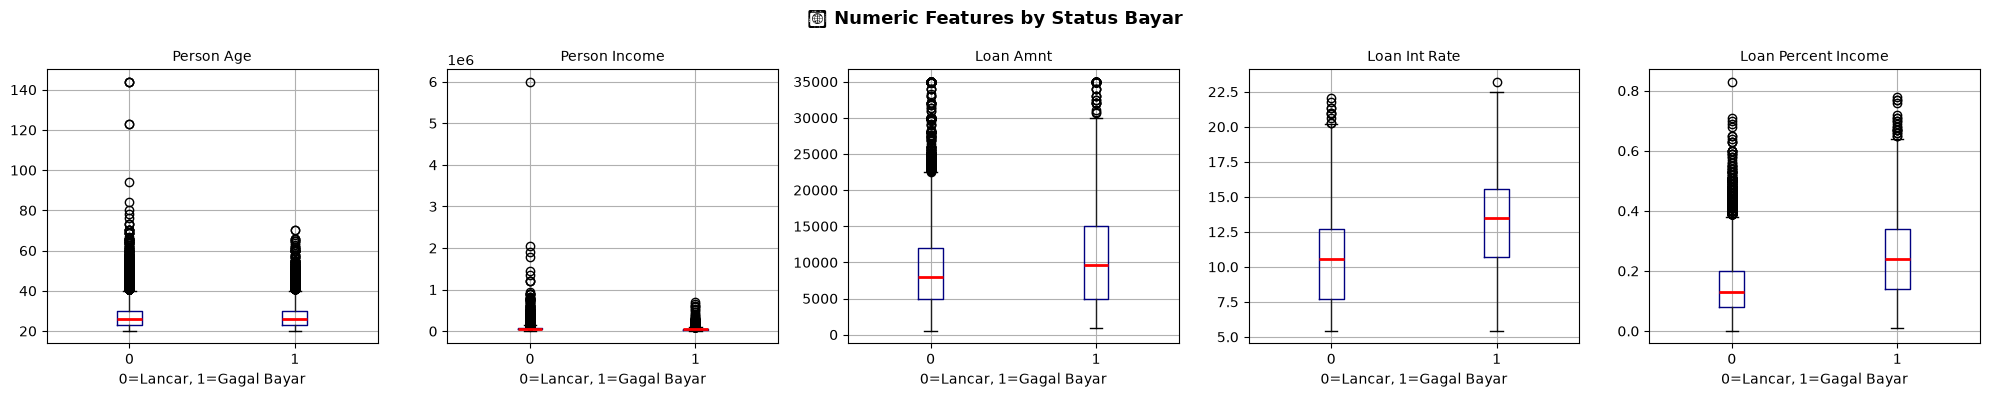

💡 Key Observations:
• Higher interest rate → higher default risk
• Higher loan_percent_income → higher default risk (loan burden)
• Lower income → slightly higher default tendency


In [4]:
import matplotlib.pyplot as plt

# Key numeric features vs default rate
num_cols = ["person_age", "person_income", "loan_amnt", "loan_int_rate", "loan_percent_income"]

fig, axes = plt.subplots(1, len(num_cols), figsize=(20,4))

for ax, col in zip(axes, num_cols):
    df.boxplot(column=col, by='loan_status', ax=ax,
               boxprops=dict(color='navy'), medianprops=dict(color='red', linewidth=2))
    ax.set_title(col.replace('_', ' ').title(), fontsize=10)
    ax.set_xlabel('0=Lancar, 1=Gagal Bayar')
    ax.set_ylabel('')
    
plt.suptitle("📦 Numeric Features by Status Bayar", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Key Observations:")
print("• Higher interest rate → higher default risk")
print("• Higher loan_percent_income → higher default risk (loan burden)")
print("• Lower income → slightly higher default tendency")

C:\Users\APTIKA\AppData\Local\Temp\ipykernel_22296\3752880914.py:22: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


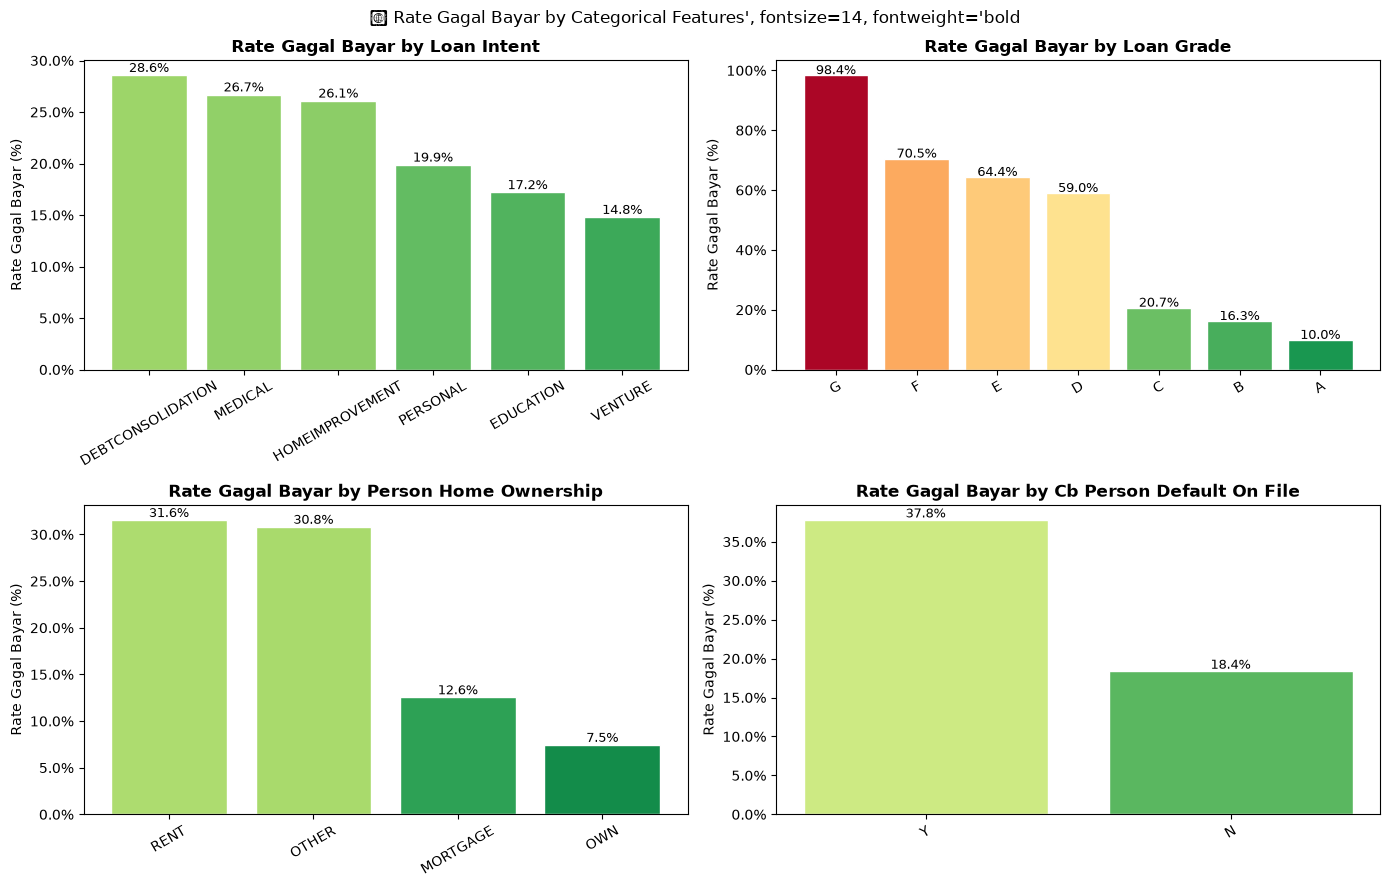

💡 Key Observations:
• Loan grade G/F has drastically higher default (gagal bayar) rates
• Borrowers with prior defaults (cb_person_default_on_file=Y) default more
• Debt consolidation and medical loans show elevated risk


In [12]:
import matplotlib.ticker as mtick

# Default rate by categorical features
cat_cols = ["loan_intent", "loan_grade", "person_home_ownership", "cb_person_default_on_file"]

fig, axes = plt.subplots(2, 2, figsize=(14,9))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    default_rate = df.groupby(col)['loan_status'].mean().sort_values(ascending=False)
    bars = ax.bar(default_rate.index, default_rate.values * 100,
                  color=plt.cm.RdYlGn_r(default_rate.values), edgecolor='white')
    ax.set_title(f'Rate Gagal Bayar by {col.replace("_", " ").title()}', fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylabel('Rate Gagal Bayar (%)')
    ax.tick_params(axis='x', rotation=30)
    for bar, val in zip(bars, default_rate.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{val*100:.1f}%', ha='center', fontsize=9)
        
plt.suptitle("📊 Rate Gagal Bayar by Categorical Features', fontsize=14, fontweight='bold")
plt.tight_layout()
plt.show()

print("💡 Key Observations:")
print("• Loan grade G/F has drastically higher default (gagal bayar) rates")
print("• Borrowers with prior defaults (cb_person_default_on_file=Y) default more")
print("• Debt consolidation and medical loans show elevated risk")